In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('student_performance_prediction.csv')
data.head()

,Student ID,Study Hours per Week,Attendance Rate,Previous Grades,Participation in Extracurricular Activities,Parent Education Level,Passed
0,S00001,12.5,NaN,75.0,Yes,Master,Yes
1,S00002,9.3,95.3,60.6,No,High School,No
2,S00003,13.2,NaN,64.0,No,Associate,Yes
3,S00004,17.6,76.8,62.4,Yes,Bachelor,Yes
4,S00005,8.8,89.3,72.7,No,Master,Yes


In [3]:
data.info()
data['Passed'].unique()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 7 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Student ID                                   40000 non-null  object 
 1   Study Hours per Week                         38005 non-null  float64
 2   Attendance Rate                              38008 non-null  float64
 3   Previous Grades                              38006 non-null  float64
 4   Participation in Extracurricular Activities  38000 non-null  object 
 5   Parent Education Level                       38000 non-null  object 
 6   Passed                                       38000 non-null  object 
dtypes: float64(3), object(4)
memory usage: 2.1+ MB


array(['Yes', 'No', nan], dtype=object)

In [4]:
for col in data.columns:
    if data[col].dtype == 'object':
        print(f"Column: {col}")
        print(data[col].value_counts())
        print("\n")

Column: Student ID
Student ID
S00001    1
S26671    1
S26664    1
S26665    1
S26666    1
         ..
S13334    1
S13335    1
S13336    1
S13337    1
S40000    1
Name: count, Length: 40000, dtype: int64


Column: Participation in Extracurricular Activities
Participation in Extracurricular Activities
No     19028
Yes    18972
Name: count, dtype: int64


Column: Parent Education Level
Parent Education Level
Bachelor       7685
High School    7675
Doctorate      7610
Associate      7604
Master         7426
Name: count, dtype: int64


Column: Passed
Passed
Yes    25264
No     12736
Name: count, dtype: int64




In [5]:
data.describe(include='all')

,Student ID,Study Hours per Week,Attendance Rate,Previous Grades,Participation in Extracurricular Activities,Parent Education Level,Passed
count,40000,38005.000000,38008.000000,38006.000000,38000,38000,38000
unique,40000,NaN,NaN,NaN,2,5,2
top,S00001,NaN,NaN,NaN,No,Bachelor,Yes
freq,1,NaN,NaN,NaN,19028,7685,25264
mean,NaN,9.962744,75.276323,65.440107,NaN,NaN,NaN
std,NaN,5.031154,20.393418,16.503119,NaN,NaN,NaN
min,NaN,-12.300000,-14.300000,8.300000,NaN,NaN,NaN
25%,NaN,6.600000,61.600000,55.100000,NaN,NaN,NaN
50%,NaN,10.000000,75.300000,65.200000,NaN,NaN,NaN
75%,NaN,13.400000,88.800000,75.200000,NaN,NaN,NaN


In [6]:
data = data.drop(columns=['Student ID'])
data.head()

,Study Hours per Week,Attendance Rate,Previous Grades,Participation in Extracurricular Activities,Parent Education Level,Passed
0,12.5,NaN,75.0,Yes,Master,Yes
1,9.3,95.3,60.6,No,High School,No
2,13.2,NaN,64.0,No,Associate,Yes
3,17.6,76.8,62.4,Yes,Bachelor,Yes
4,8.8,89.3,72.7,No,Master,Yes


In [7]:
# replace nan value in nominal columns with its mode value

mode_parent_education = data['Parent Education Level'].mode()[0]
mode_participation = data['Participation in Extracurricular Activities'].mode()[0]
# print(f"Mode of Parent Education Level: {mode_parent_education}")
# print(f"Mode of Participation in Extracurricular Activities: {mode_participation}")
data['Parent Education Level'] = data['Parent Education Level'].fillna(mode_parent_education)
data['Participation in Extracurricular Activities'] = data['Participation in Extracurricular Activities'].fillna(mode_participation)
# data['Parent Education Level'].isnull().sum()

In [8]:
# TODO: try to use regression to fix invalid values in Previous Grades, Attendance Rate, and Study Hours
# for now convert all invalid values to nan
data['Previous Grades'] = data['Previous Grades'].mask(
    (data['Previous Grades'] < 0) | (data['Previous Grades'] > 100)
)
data['Attendance Rate'] = data['Attendance Rate'].mask(
    (data['Attendance Rate'] < 0) | (data['Attendance Rate'] > 100)
)
data['Study Hours per Week'] = data['Study Hours per Week'].mask(
    data['Study Hours per Week'] < 0
)
print(data['Previous Grades'].isnull().sum(), data['Attendance Rate'].isnull().sum(), data['Study Hours per Week'].isnull().sum())

data = data[data['Passed'].notnull()]
data['Passed'].map({'Yes': 1, 'No': 0})
data_test_median = data.copy()
# data.head()

2475 6134 2936


Median previous grade: 64.9
       K value  Median Impute   KNN Impute  Original Valid Data
count        1   2.340000e+03  2340.000000         35660.000000
mean         1   6.490000e+01    63.728231            64.672925
std          1   2.871206e-12    16.470088            14.509373
min          1   6.490000e+01    16.300000             8.300000
25%          1   6.490000e+01    52.200000            54.900000
50%          1   6.490000e+01    63.000000            64.900000
75%          1   6.490000e+01    76.000000            74.700000
max          1   6.490000e+01    99.900000           100.000000
       K value  Median Impute   KNN Impute  Original Valid Data
count        2   2.340000e+03  2340.000000         35660.000000
mean         2   6.490000e+01    64.087975            64.672925
std          2   2.871206e-12    12.178345            14.509373
min          2   6.490000e+01    23.500000             8.300000
25%          2   6.490000e+01    55.987500            54.900000
50%         

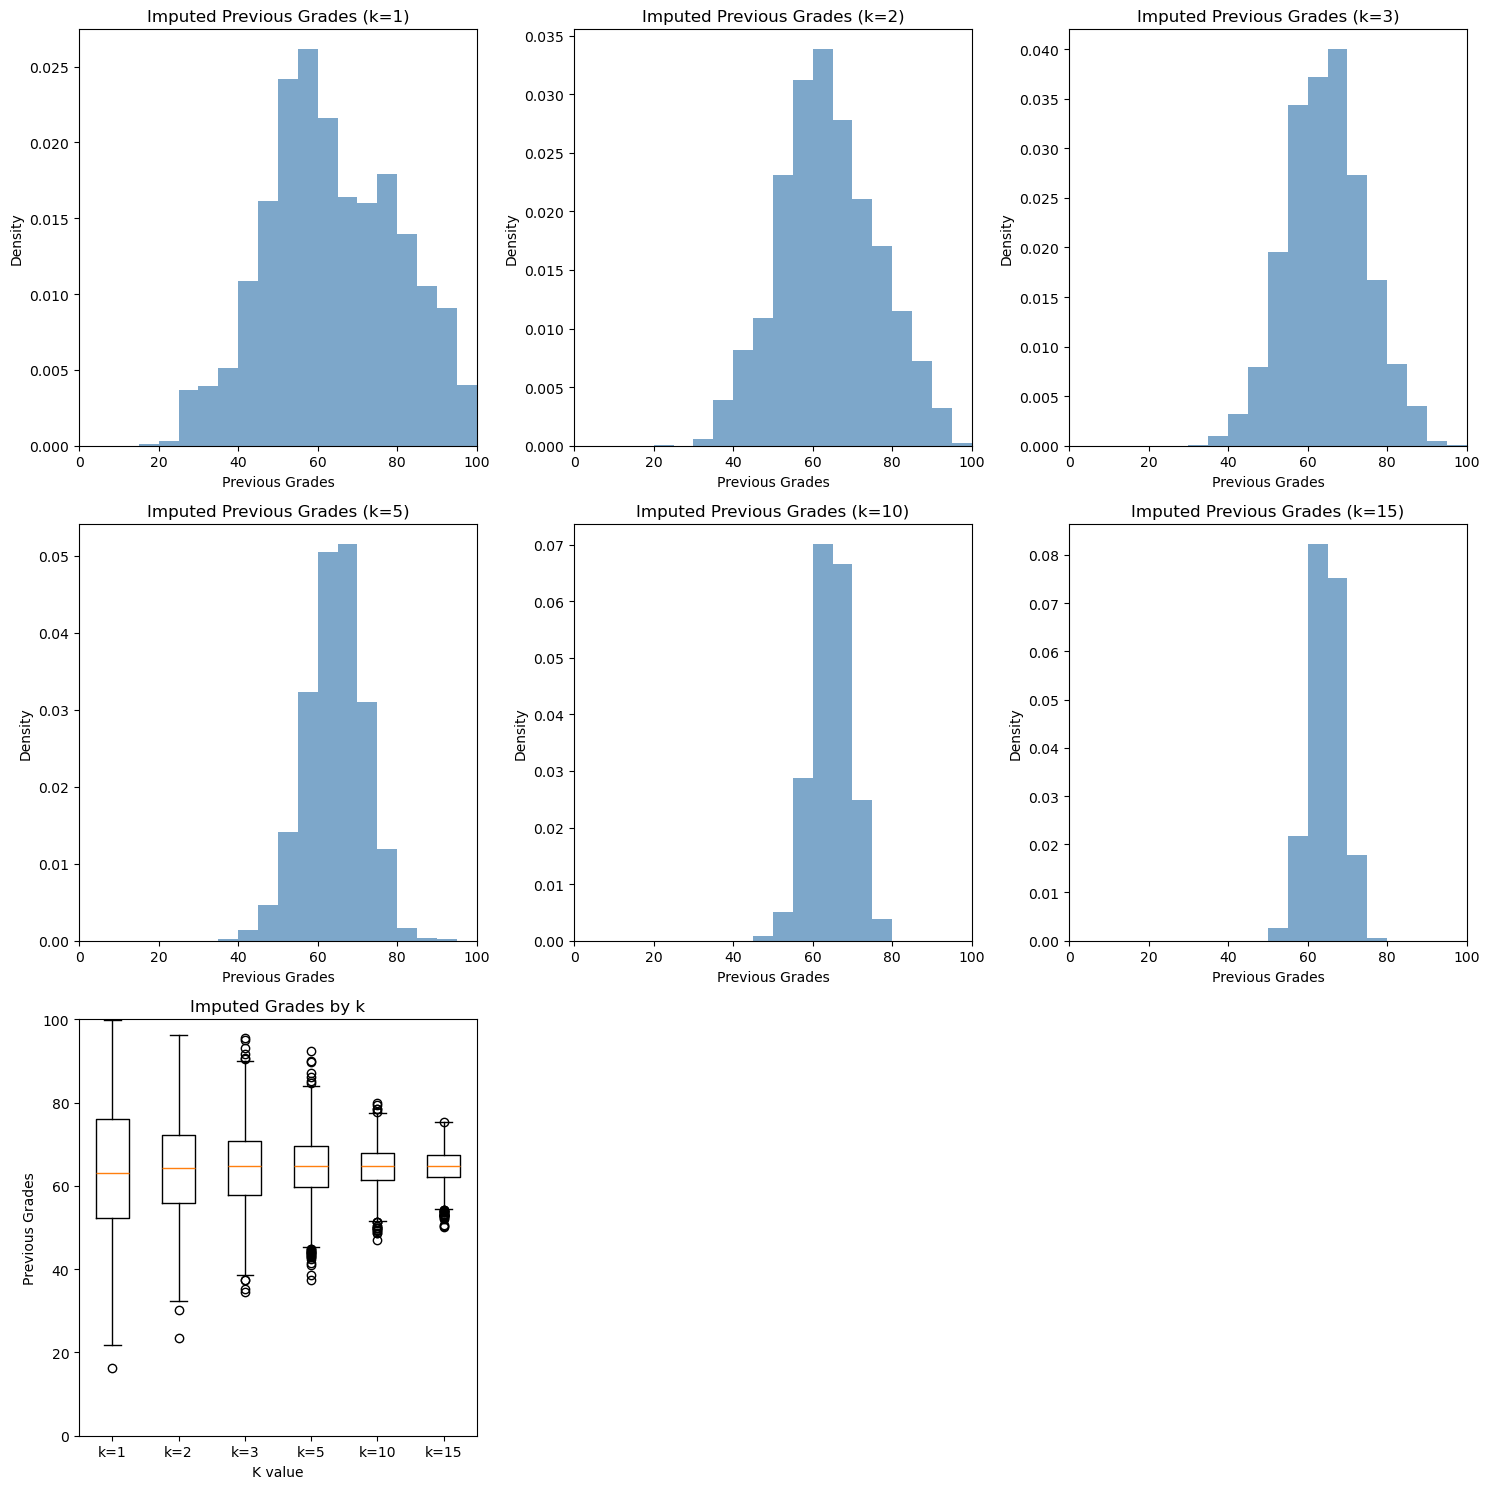

In [9]:
# fix 1: regression to fix invalid values in Previous Grades, Attendance Rate, and Study Hours columns by columns
# use KNNImputer to fill in missing values
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

features = ['Previous Grades', 'Attendance Rate', 'Study Hours per Week']
X_clean = data[features].copy()

# get masks for statistics (test with Previous Grades)
X_clean['Previous Grades'] = X_clean['Previous Grades'].mask(
    (X_clean['Previous Grades'] < 0) | (X_clean['Previous Grades'] > 100)
)
missing_mask_1 = X_clean['Previous Grades'].isna()

# get median baseline
median_val = X_clean['Previous Grades'].median()
print(f"Median previous grade: {median_val}")
median_imputed_subset = pd.Series(median_val, index=X_clean[missing_mask_1].index)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean[features])

# test the dataset with some k values to choose the best one
# in theory the lower k is the more diverse the final distribution is
k_values = [1, 2, 3, 5, 10, 15]
X_imputeds = {}
imputed_results = {}
for k in k_values:
    KNN_imputer = KNNImputer(n_neighbors=k)
    X_imputed = KNN_imputer.fit_transform(X_scaled)
    X_imputed_original = scaler.inverse_transform(X_imputed)

    knn_imputed_subset_1 = pd.Series(
        X_imputed_original[missing_mask_1, 0], index=data[missing_mask_1].index
    )
    X_imputeds[k] = X_imputed_original
    imputed_results[k] = knn_imputed_subset_1

    comparison_grades = pd.DataFrame(
        {
            'K value': k,
            'Median Impute': median_imputed_subset.describe(),
            'KNN Impute': knn_imputed_subset_1.describe(),
            'Original Valid Data': data['Previous Grades'].dropna().describe(),
        }
    )
    print(comparison_grades)

# Compare the distribution of imputed Previous Grades for each k value.
ncols = 3
nrows = int(np.ceil((len(k_values) + 1) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 5 * nrows))
axes = np.asarray(axes).reshape(-1)
bins = np.linspace(0, 100, 21)

for ax, (k, values) in zip(axes, imputed_results.items()):
    if not values.empty:
        ax.hist(values, bins=bins, density=True, alpha=0.7, color="steelblue")
    else:
        ax.text(0.5, 0.5, "No values imputed", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"Imputed Previous Grades (k={k})")
    ax.set_xlabel("Previous Grades")
    ax.set_ylabel("Density")
    ax.set_xlim(0, 100)

non_empty_results = {
    f"k={k}": values.to_numpy()
    for k, values in imputed_results.items()
    if not values.empty
}
boxplot_ax = axes[len(k_values)]
if non_empty_results:
    boxplot_ax.boxplot(non_empty_results.values(), tick_labels=non_empty_results.keys())
boxplot_ax.set_title("Imputed Grades by k")
boxplot_ax.set_xlabel("K value")
boxplot_ax.set_ylabel("Previous Grades")
boxplot_ax.set_ylim(0, 100)

for ax in axes[len(k_values) + 1:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


In [10]:
# In the plots above we see that the theory is correct, the lower the k value is the more preserved the distribution is
# The overfitting problem has been solved

data[features] = X_imputeds[3]
print(data['Previous Grades'].isnull().sum(), data['Attendance Rate'].isnull().sum(), data['Study Hours per Week'].isnull().sum())

0 0 0


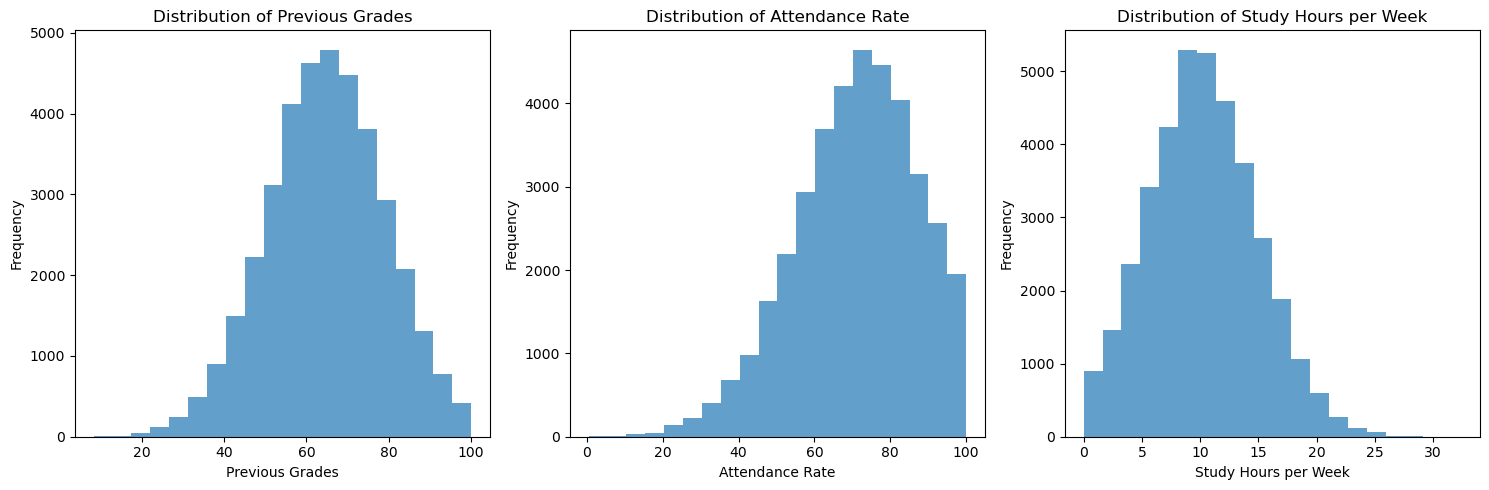

In [11]:
# plot the newly filled values for Previous Grades, Attendance Rate, and Study Hours per Week
plt.figure(figsize=(15, 5))

for i, feature in enumerate(features):
    plt.subplot(1, 3, i + 1)
    plt.hist(data[feature], bins=20, alpha=0.7)
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.title(f'Distribution of {feature}')

plt.tight_layout()
plt.show()

In [12]:
# update the csv file with the cleaned data
data.to_csv('student_performance_prediction_cleaned.csv', index=False)